In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from russian_rates.analysis import align_ruonia_with_key_rate
from russian_rates.models import (
    prepare_transitions,
    calibrate_profile,
    conditional_moments,
)

In [2]:
ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file()
)

data_dir = ROOT / "data" / "processed"

ruonia = pd.read_parquet(data_dir / "ruonia.parquet")
key_rate = pd.read_parquet(data_dir / "key_rate.parquet")

df = align_ruonia_with_key_rate(ruonia, key_rate)
df = df.dropna(subset=["spread_pp"])
df = df.sort_values("date").reset_index(drop=True)

train = df[df["date"] >= "2023-01-01"]

r0, r1, dt = prepare_transitions(
    train, "spread_pp"
)

fit = calibrate_profile(
    r0, r1, dt,
    a_bounds=(0.001, 200.0)
)

a = fit["a"]
b = fit["b"]
sigma = fit["sigma"]

# Последние наблюдаемые значения
s0 = df["spread_pp"].iloc[-1] / 100
key0 = df["key_rate_pct"].iloc[-1]
start_date = df["date"].iloc[-1]

print(f"a = {a:.4f}")
print(f"b = {b * 100:.4f} п.п.")
print(f"sigma = {sigma * 100:.4f} п.п./√год")
print(f"Начальный спред = {s0 * 100:.4f} п.п.")
print(f"Последняя ключевая ставка = {key0:.2f}%")
print(f"Дата начала: {start_date.date()}")

a = 42.8224
b = -0.2113 п.п.
sigma = 2.9518 п.п./√год
Начальный спред = 0.0700 п.п.
Последняя ключевая ставка = 14.00%
Дата начала: 2026-11-20


In [3]:
n_paths = 10_000
horizon_days = 90

rng = np.random.default_rng(42)

dates = pd.date_range(
    start=start_date,
    periods=horizon_days + 1,
    freq="D",
)

paths = np.empty((horizon_days + 1, n_paths))

# Все траектории начинаются с одного спреда
paths[0, :] = s0

for t in range(1, len(dates)):

    delta_t = (dates[t] - dates[t - 1]).days / 365

    mu, var = conditional_moments(
        a, b, sigma,
        paths[t - 1, :],
        delta_t,
    )

    shocks = rng.standard_normal(n_paths)

    paths[t, :] = mu + np.sqrt(var) * shocks

print("Размер массива:", paths.shape)

Размер массива: (91, 10000)


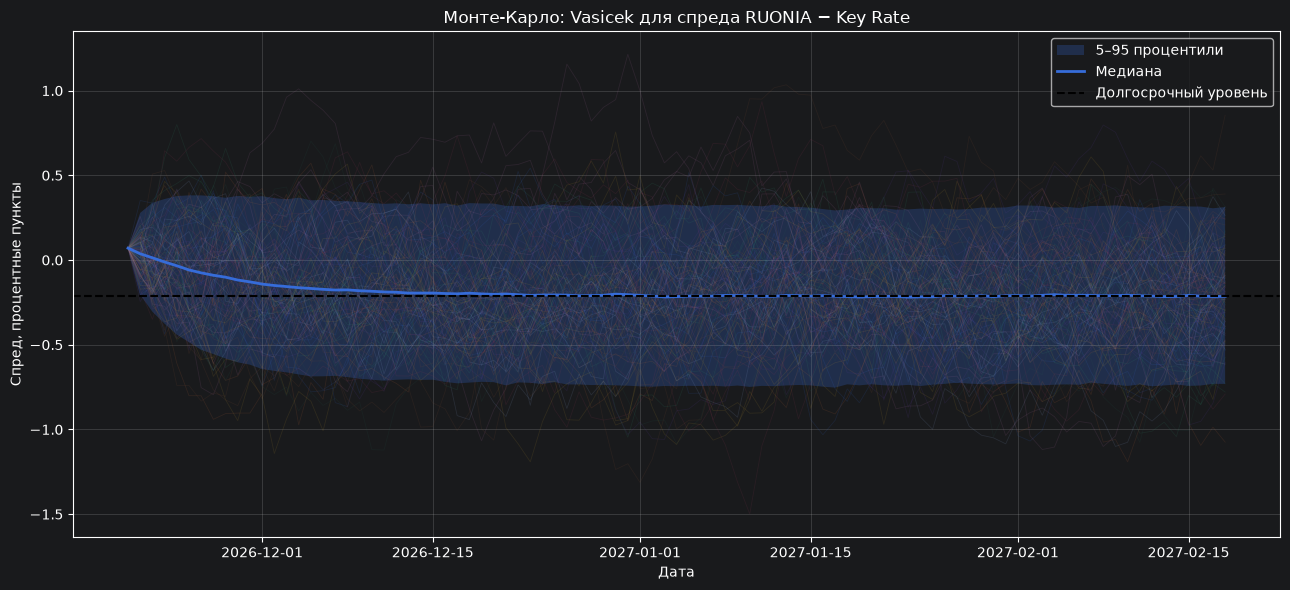

In [5]:
# Переводим спред обратно в процентные пункты
spread_paths = paths * 100

q05, q50, q95 = np.quantile(
    spread_paths,
    [0.05, 0.50, 0.95],
    axis=1
)

plt.figure(figsize=(13, 6))

# Показываем 100 отдельных траекторий
plt.plot(
    dates,
    spread_paths[:, :100],
    alpha=0.12,
    linewidth=0.6
)

plt.fill_between(
    dates,
    q05,
    q95,
    alpha=0.25,
    label="5–95 процентили"
)

plt.plot(
    dates,
    q50,
    linewidth=2,
    label="Медиана"
)

plt.axhline(
    b * 100,
    linestyle="--",
    color="black",
    label="Долгосрочный уровень"
)

plt.title("Монте-Карло: Vasicek для спреда RUONIA − Key Rate")
plt.ylabel("Спред, процентные пункты")
plt.xlabel("Дата")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
T = horizon_days / 365

mu_T, var_T = conditional_moments(
    a, b, sigma,
    s0, T
)

print("Через 90 календарных дней:")
print()

print("Аналитическое ожидание:",
      round(float(mu_T) * 100, 4), "п.п.")

print("Среднее Монте-Карло:",
      round(spread_paths[-1].mean(), 4), "п.п.")

print()
print("Аналитическое Std:",
      round(float(np.sqrt(var_T)) * 100, 4), "п.п.")

print("Std Монте-Карло:",
      round(spread_paths[-1].std(ddof=1), 4), "п.п.")

Через 90 календарных дней:

Аналитическое ожидание: -0.2113 п.п.
Среднее Монте-Карло: -0.2112 п.п.

Аналитическое Std: 0.319 п.п.
Std Монте-Карло: 0.3189 п.п.
